# Facial Expression Recognition on FER-2013
## Final Submission Notebook (all phases, executed)

**Group 4, SEP 740 Deep Learning, McMaster University**  
Zoheb Abdur Rahman · Daniel Wong · Mahan Choudhury · Kevin Zhang · Omar Tawalbeh

This single notebook contains the complete project with executed results: Phase 1 data pipeline (Kevin/Omar), Phase 2 model development (Daniel/Kevin), Phase 3 Optuna tuning and ablations (Mahan), Phase 4 evaluation and FGSM robustness (Zoheb/Mahan), and Phase 5 adversarial-training defence and webcam demo export (Daniel). Outputs were merged from the group's executed runs (identical artifacts, seed 42). See README.txt for dataset download and how to re-run.

# FER-2013 Facial Expression Recognition — Complete Pipeline
**Group 4 · SEP 740 Project 21 · All phases in one notebook**

This notebook combines Phases 1 to 5 end to end: data pipeline, model development, hyperparameter tuning and ablations, evaluation and robustness, and security analysis with the demo export. It uses the same `fer_lib.py` and the same `artifacts/` handoff as the per-phase notebooks, so results are interchangeable between this file and the individual ones. Run top to bottom; the setup cell appears once at the start.

Requirements: `data/fer2013.csv` and (optionally) `data/fer2013new.csv`, plus the packages in the README. Reduce the epoch/trial constants for a dry run.

## Environment setup (Colab-ready — no Drive mount, no separate uploads)

Run this notebook **top to bottom**. The next two cells make it fully self-contained: the first recreates `fer_lib.py` (all shared code) inside the runtime, and the second downloads FER-2013 + FERPlus from public mirrors and checksum-verifies them. The only file you upload is *this notebook* — no `fer_lib.py`, no dataset, no Google Drive mount.

On Colab, pick a GPU runtime for the training phases (**Runtime → Change runtime type → GPU**).

In [18]:
%%writefile fer_lib.py
"""Shared library for the phase notebooks (Group 4, SEP 740 Project 21).

Implements everything the finalized proposal requires:
- FER-2013 loading (official Training / PublicTest / PrivateTest splits)
- FERPlus majority-vote relabeling for cross-dataset evaluation
- preprocessing, augmentation, inverse-frequency class weighting
- model zoo: BaselineCNN, DeepFERNet (residual + SE attention),
  fine-tuned ResNet-18, and reference architectures adapted to
  single-channel 48x48 input: LeNet, VGG-16, ResNet-18 (scratch), ConvNeXt-Tiny
- training loop (AdamW / SGD+Nesterov, cosine schedule, early stopping)
- evaluation helpers (macro metrics, confusion matrix, bootstrap CI)
- FGSM attack and robustness sweep
- artifact manifest so each phase hands results to the next

Every phase notebook does `from fer_lib import *`.
"""

import json
import os
import random
from datetime import datetime

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import models as tv_models, transforms

# ------------------------------------------------------------------ constants
EMOTIONS = ["Angry", "Disgust", "Fear", "Happy", "Sad", "Surprise", "Neutral"]
NUM_CLASSES = 7
IMG_SIZE = 48
FER_MEAN, FER_STD = 0.5077, 0.255
NORM_MIN = (0.0 - FER_MEAN) / FER_STD
NORM_MAX = (1.0 - FER_MEAN) / FER_STD

# FERPlus vote columns (fer2013new.csv), aligned row-wise with fer2013.csv.
FERPLUS_COLS = ["neutral", "happiness", "surprise", "sadness", "anger",
                "disgust", "fear", "contempt", "unknown", "NF"]
# Map the 7 overlapping FERPlus emotions onto FER-2013 label indices.
FERPLUS_TO_FER = {"anger": 0, "disgust": 1, "fear": 2, "happiness": 3,
                  "sadness": 4, "surprise": 5, "neutral": 6}

ARTIFACTS = "artifacts"   # handoff directory shared by all phases


# ------------------------------------------------------------------ utilities
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def denormalize(t: torch.Tensor) -> torch.Tensor:
    return (t * FER_STD + FER_MEAN).clamp(0, 1)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# ------------------------------------------------------- artifact manifest
def _manifest_path():
    return os.path.join(ARTIFACTS, "manifest.json")


def load_manifest() -> dict:
    if os.path.exists(_manifest_path()):
        with open(_manifest_path()) as f:
            return json.load(f)
    return {}


def update_manifest(phase: str, entries: dict):
    """Record what a phase produced so the next phase can pick it up."""
    os.makedirs(ARTIFACTS, exist_ok=True)
    m = load_manifest()
    m.setdefault(phase, {}).update(entries)
    m[phase]["updated"] = datetime.now().isoformat(timespec="seconds")
    with open(_manifest_path(), "w") as f:
        json.dump(m, f, indent=2)
    print(f"[manifest] {phase}: {sorted(entries.keys())}")


def require_artifact(phase: str, key: str):
    """Fetch an artifact recorded by an earlier phase, with a clear error."""
    m = load_manifest()
    if phase not in m or key not in m[phase]:
        raise RuntimeError(
            f"Artifact '{key}' from {phase} not found. Run the {phase} notebook first.")
    return m[phase][key]


# ------------------------------------------------------------------ datasets
def parse_pixels(s: str) -> np.ndarray:
    """Decode one `pixels` cell ("70 80 82 ...") into a 48x48 uint8 image."""
    try:
        flat = np.fromstring(s, dtype=np.uint8, sep=" ")   # C-fast path
    except (DeprecationWarning, ValueError, AttributeError):
        flat = np.array(s.split(), dtype=np.uint8)         # future-proof fallback
    if flat.size != IMG_SIZE * IMG_SIZE:
        raise ValueError(
            f"expected {IMG_SIZE * IMG_SIZE} pixel values, got {flat.size}. "
            "This does not look like the original FER-2013 csv.")
    return flat.reshape(IMG_SIZE, IMG_SIZE)


_CSV_CACHE = {}   # {path: DataFrame} -- holds at most one entry


def clear_fer_cache():
    """Drop the cached FER-2013 DataFrame (frees ~300 MB)."""
    _CSV_CACHE.clear()


def read_fer_csv(csv_path: str, use_cache: bool = True) -> pd.DataFrame:
    """Read fer2013.csv with column normalization, validation and caching.

    Kaggle ships two variants of this file: `fer2013.csv` with the header
    `emotion,pixels,Usage`, and `icml_face_data.csv` with `emotion, Usage,
    pixels` -- note the leading spaces, which silently break `df["pixels"]`.
    Both are accepted here. The parsed frame is cached because the phase
    notebooks read the same 300 MB file several times.
    """
    if use_cache and csv_path in _CSV_CACHE:
        return _CSV_CACHE[csv_path]

    if not os.path.exists(csv_path):
        raise FileNotFoundError(
            f"FER-2013 csv not found at '{csv_path}'.\n"
            "Download the original fer2013.csv (~290 MB, 35887 rows) and place "
            f"it there. It must have the columns emotion, pixels, Usage.")

    df = pd.read_csv(csv_path)
    df.columns = [c.strip() for c in df.columns]           # ' pixels' -> 'pixels'

    missing = {"emotion", "pixels", "Usage"} - set(df.columns)
    if missing:
        raise ValueError(
            f"'{csv_path}' is missing column(s) {sorted(missing)}; found "
            f"{list(df.columns)}.\nThis is probably the wrong FER-2013 "
            "download (the image-folder versions have no csv, and some "
            "reuploads drop the Usage split). Use the original fer2013.csv.")

    usages = set(df["Usage"].unique())
    if not usages <= {"Training", "PublicTest", "PrivateTest"}:
        raise ValueError(
            f"unexpected Usage values in '{csv_path}': {sorted(usages)}. "
            "Expected Training / PublicTest / PrivateTest.")

    if use_cache:
        _CSV_CACHE.clear()          # keep only the most recent file
        _CSV_CACHE[csv_path] = df
    return df


def build_transforms(train: bool, augment: bool = True):
    normalize = transforms.Normalize(mean=[FER_MEAN], std=[FER_STD])
    if train and augment:
        return transforms.Compose([
            transforms.Grayscale(1),
            transforms.RandomHorizontalFlip(0.5),
            transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
            transforms.ColorJitter(brightness=0.2),
            transforms.ToTensor(),
            normalize,
            transforms.RandomErasing(p=0.25, scale=(0.02, 0.1)),
        ])
    return transforms.Compose([transforms.Grayscale(1), transforms.ToTensor(), normalize])


class FER2013CSV(Dataset):
    """Original fer2013.csv. Usage: Training / PublicTest / PrivateTest.

    `override_labels` swaps in alternative labels (e.g., FERPlus majority
    votes) while keeping the same images; rows with label -1 are dropped.
    """

    def __init__(self, csv_path, usage, transform=None, override_labels=None):
        df = read_fer_csv(csv_path)
        mask = (df["Usage"] == usage).values
        labels = df["emotion"].values.astype(np.int64)
        pixels = df["pixels"].values
        if override_labels is not None:
            labels = np.asarray(override_labels, dtype=np.int64)
            if len(labels) != len(df):
                raise ValueError(
                    f"override_labels has {len(labels)} entries but "
                    f"'{csv_path}' has {len(df)} rows; they must be row-aligned.")
        keep = mask & (labels >= 0)
        self.labels = labels[keep]
        self.pixels = [parse_pixels(p) for p in pixels[keep]]
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = Image.fromarray(self.pixels[idx], mode="L")
        if self.transform:
            img = self.transform(img)
        return img, int(self.labels[idx])


def ferplus_majority_labels(ferplus_csv: str) -> np.ndarray:
    """Majority-vote FERPlus labels mapped to FER-2013 indices.

    Returns one label per fer2013.csv row: -1 where the majority is
    contempt / unknown / NF or where votes are missing, otherwise 0..6.
    """
    if not os.path.exists(ferplus_csv):
        raise FileNotFoundError(
            f"FERPlus labels not found at '{ferplus_csv}'. Download with:\n"
            "  curl -L -o data/fer2013new.csv "
            "https://raw.githubusercontent.com/microsoft/FERPlus/master/fer2013new.csv")
    fp = pd.read_csv(ferplus_csv)
    fp.columns = [c.strip() for c in fp.columns]
    missing = set(FERPLUS_COLS) - set(fp.columns)
    if missing:
        raise ValueError(
            f"'{ferplus_csv}' is missing vote column(s) {sorted(missing)}; "
            f"found {list(fp.columns)}. Expected microsoft/FERPlus fer2013new.csv.")
    votes = fp[FERPLUS_COLS].values
    winner = votes.argmax(axis=1)
    labels = np.full(len(fp), -1, dtype=np.int64)
    for i, w in enumerate(winner):
        name = FERPLUS_COLS[w]
        if name in FERPLUS_TO_FER and votes[i].sum() > 0:
            labels[i] = FERPLUS_TO_FER[name]
    return labels


def get_dataloaders(data_csv, batch_size=64, augment=True, num_workers=2,
                    override_labels=None):
    """train/val/test loaders on the official splits + class weights."""
    train_tf = build_transforms(True, augment)
    eval_tf = build_transforms(False)
    train_ds = FER2013CSV(data_csv, "Training", train_tf, override_labels)
    val_ds = FER2013CSV(data_csv, "PublicTest", eval_tf, override_labels)
    test_ds = FER2013CSV(data_csv, "PrivateTest", eval_tf, override_labels)

    counts = np.bincount(train_ds.labels, minlength=NUM_CLASSES).astype(np.float64)
    class_weights = torch.tensor(counts.sum() / (NUM_CLASSES * np.maximum(counts, 1)),
                                 dtype=torch.float32)
    common = dict(batch_size=batch_size, num_workers=num_workers, pin_memory=True)
    return (DataLoader(train_ds, shuffle=True, drop_last=True, **common),
            DataLoader(val_ds, shuffle=False, **common),
            DataLoader(test_ds, shuffle=False, **common),
            class_weights)


# ------------------------------------------------------------------ models
def conv_block(in_ch, out_ch, pool=True, p_drop=0.0):
    layers = [nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
              nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
              nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
              nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True)]
    if pool:
        layers.append(nn.MaxPool2d(2))
    if p_drop > 0:
        layers.append(nn.Dropout2d(p_drop))
    return nn.Sequential(*layers)


class BaselineCNN(nn.Module):
    """3-block VGG-style CNN with BN + dropout (LeNet/VGG-16 inspired)."""

    def __init__(self, num_classes=7, dropout=0.4):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(1, 32, p_drop=dropout * 0.5),
            conv_block(32, 64, p_drop=dropout * 0.5),
            conv_block(64, 128, p_drop=dropout * 0.5))
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(128 * 6 * 6, 256), nn.BatchNorm1d(256),
            nn.ReLU(inplace=True), nn.Dropout(dropout), nn.Linear(256, num_classes))

    def forward(self, x):
        return self.classifier(self.features(x))


class SEBlock(nn.Module):
    """Squeeze-and-Excitation channel attention."""

    def __init__(self, channels, reduction=16):
        super().__init__()
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(channels, max(channels // reduction, 4)), nn.ReLU(inplace=True),
            nn.Linear(max(channels // reduction, 4), channels), nn.Sigmoid())

    def forward(self, x):
        b, c, _, _ = x.shape
        return x * self.fc(self.pool(x).view(b, c)).view(b, c, 1, 1)


class ResidualBlock(nn.Module):
    def __init__(self, channels, use_attention=True):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(channels), nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(channels))
        self.se = SEBlock(channels) if use_attention else nn.Identity()
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.relu(x + self.se(self.body(x)))


class DeepFERNet(nn.Module):
    """Modified architecture: residual connections + SE attention (ResNet/ConvNeXt guided)."""

    def __init__(self, num_classes=7, dropout=0.4, use_attention=True, n_stages=4):
        super().__init__()
        widths = [64, 128, 256, 512][:n_stages]
        stages, in_ch = [], 1
        for w in widths:
            stages += [conv_block(in_ch, w, pool=True, p_drop=dropout * 0.5),
                       ResidualBlock(w, use_attention)]
            in_ch = w
        self.features = nn.Sequential(*stages)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                  nn.Dropout(dropout), nn.Linear(widths[-1], num_classes))

    def forward(self, x):
        return self.head(self.features(x))


def build_resnet18_finetune(num_classes=7, dropout=0.4):
    """ImageNet-pretrained ResNet-18 fine-tuned for 1-channel 48x48 input."""
    net = tv_models.resnet18(weights=tv_models.ResNet18_Weights.IMAGENET1K_V1)
    old = net.conv1
    net.conv1 = nn.Conv2d(1, 64, 7, stride=1, padding=3, bias=False)
    with torch.no_grad():
        net.conv1.weight.copy_(old.weight.mean(dim=1, keepdim=True))
    net.maxpool = nn.Identity()
    net.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(net.fc.in_features, num_classes))
    return net


# ----- reference architectures (comparative analysis, trained from scratch)
class LeNetGray(nn.Module):
    """LeNet-5 adapted to 48x48 grayscale."""

    def __init__(self, num_classes=7, dropout=0.0):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, 5), nn.ReLU(inplace=True), nn.MaxPool2d(2),   # 22
            nn.Conv2d(6, 16, 5), nn.ReLU(inplace=True), nn.MaxPool2d(2))  # 9
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(16 * 9 * 9, 120), nn.ReLU(inplace=True),
            nn.Linear(120, 84), nn.ReLU(inplace=True),
            nn.Dropout(dropout), nn.Linear(84, num_classes))

    def forward(self, x):
        return self.classifier(self.features(x))


def build_vgg16_gray(num_classes=7, dropout=0.4):
    """VGG-16 (from scratch) with the stem adapted to 1-channel 48x48."""
    net = tv_models.vgg16_bn(weights=None)
    net.features[0] = nn.Conv2d(1, 64, 3, padding=1)
    net.avgpool = nn.AdaptiveAvgPool2d(1)
    net.classifier = nn.Sequential(
        nn.Linear(512, 256), nn.ReLU(inplace=True),
        nn.Dropout(dropout), nn.Linear(256, num_classes))
    return net


def build_resnet18_scratch(num_classes=7, dropout=0.4):
    """ResNet-18 trained from scratch (no ImageNet weights), 1-channel stem."""
    net = tv_models.resnet18(weights=None)
    net.conv1 = nn.Conv2d(1, 64, 7, stride=1, padding=3, bias=False)
    net.maxpool = nn.Identity()
    net.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(net.fc.in_features, num_classes))
    return net


def build_convnext_tiny_gray(num_classes=7, dropout=0.4):
    """ConvNeXt-Tiny with the stem adapted to 1-channel 48x48 (stride 2)."""
    net = tv_models.convnext_tiny(weights=None)
    net.features[0][0] = nn.Conv2d(1, 96, kernel_size=2, stride=2)  # 48 -> 24
    net.classifier[2] = nn.Linear(net.classifier[2].in_features, num_classes)
    return net


MODEL_REGISTRY = {
    "baseline": lambda dropout=0.4, **kw: BaselineCNN(NUM_CLASSES, dropout),
    "deepfernet": lambda dropout=0.4, **kw: DeepFERNet(NUM_CLASSES, dropout, True),
    "deepfernet_noattn": lambda dropout=0.4, **kw: DeepFERNet(NUM_CLASSES, dropout, False),
    "deepfernet_3stage": lambda dropout=0.4, **kw: DeepFERNet(NUM_CLASSES, dropout, True, n_stages=3),
    "resnet18_ft": lambda dropout=0.4, **kw: build_resnet18_finetune(NUM_CLASSES, dropout),
    "lenet": lambda dropout=0.0, **kw: LeNetGray(NUM_CLASSES, dropout),
    "vgg16": lambda dropout=0.4, **kw: build_vgg16_gray(NUM_CLASSES, dropout),
    "resnet18_scratch": lambda dropout=0.4, **kw: build_resnet18_scratch(NUM_CLASSES, dropout),
    "convnext_tiny": lambda dropout=0.4, **kw: build_convnext_tiny_gray(NUM_CLASSES, dropout),
}


def build_model(name, **kwargs):
    if name not in MODEL_REGISTRY:
        raise ValueError(f"Unknown model '{name}'. Options: {sorted(MODEL_REGISTRY)}")
    return MODEL_REGISTRY[name](**kwargs)


# ------------------------------------------------------------------ training
def run_epoch(model, loader, criterion, device, optimizer=None):
    training = optimizer is not None
    model.train(training)
    tot_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            tot_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            n += labels.size(0)
    return tot_loss / n, correct / n


def train_model(model, train_loader, val_loader, device, epochs=30, lr=1e-3,
                weight_decay=1e-4, class_weights=None, optimizer_name="adamw",
                patience=10, ckpt_path="best.pt", verbose=True, trial=None):
    """Training loop. If an Optuna `trial` is passed, reports for pruning."""
    criterion = nn.CrossEntropyLoss(
        weight=class_weights.to(device) if class_weights is not None else None)
    if optimizer_name == "sgd":
        optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9,
                                    weight_decay=weight_decay, nesterov=True)
    else:
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr,
                                      weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_acc, stale = 0.0, 0
    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, device, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion, device)
        scheduler.step()
        for k, v in zip(history, [tr_loss, tr_acc, va_loss, va_acc]):
            history[k].append(v)
        if verbose:
            print(f"Epoch {epoch:3d}/{epochs} | train {tr_loss:.4f}/{tr_acc:.4f}"
                  f" | val {va_loss:.4f}/{va_acc:.4f}")
        if trial is not None:
            import optuna
            trial.report(va_acc, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()
        if va_acc > best_acc:
            best_acc, stale = va_acc, 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            stale += 1
            if stale >= patience:
                if verbose:
                    print(f"Early stop at epoch {epoch} (best val acc {best_acc:.4f})")
                break
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    return history, best_acc


# ---------------------------------------------------------------- evaluation
@torch.no_grad()
def collect_predictions(model, loader, device):
    model.eval()
    preds, labels = [], []
    for images, y in loader:
        preds.append(model(images.to(device)).argmax(1).cpu().numpy())
        labels.append(y.numpy())
    return np.concatenate(preds), np.concatenate(labels)


def full_metrics(preds, labels) -> dict:
    from sklearn.metrics import precision_recall_fscore_support
    acc = float((preds == labels).mean())
    mp, mr, mf1, _ = precision_recall_fscore_support(labels, preds, average="macro",
                                                     zero_division=0)
    wp, wr, wf1, _ = precision_recall_fscore_support(labels, preds, average="weighted",
                                                     zero_division=0)
    return {"accuracy": acc, "macro_precision": float(mp), "macro_recall": float(mr),
            "macro_f1": float(mf1), "weighted_f1": float(wf1)}


def bootstrap_accuracy_ci(preds, labels, n_boot=1000, alpha=0.05, seed=0):
    """Percentile bootstrap confidence interval for accuracy."""
    rng = np.random.default_rng(seed)
    n = len(labels)
    accs = [(preds[idx] == labels[idx]).mean()
            for idx in (rng.integers(0, n, n) for _ in range(n_boot))]
    lo, hi = np.percentile(accs, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(lo), float(hi)


# --------------------------------------------------------------- adversarial
def fgsm_attack(model, images, labels, epsilon, criterion):
    """FGSM in [0,1] pixel units, applied in normalized space."""
    images = images.clone().detach().requires_grad_(True)
    loss = criterion(model(images), labels)
    model.zero_grad(set_to_none=True)
    loss.backward()
    adv = images + (epsilon / FER_STD) * images.grad.sign()
    return adv.clamp(NORM_MIN, NORM_MAX).detach()


def evaluate_robustness(model, loader, device, epsilons, max_batches=50):
    criterion = nn.CrossEntropyLoss()
    model.eval()
    results = {}
    for eps in epsilons:
        correct, total = 0, 0
        for b, (images, labels) in enumerate(loader):
            if b >= max_batches:
                break
            images, labels = images.to(device), labels.to(device)
            adv = images if eps == 0 else fgsm_attack(model, images, labels, eps, criterion)
            with torch.no_grad():
                correct += (model(adv).argmax(1) == labels).sum().item()
            total += labels.size(0)
        results[float(eps)] = correct / total
        print(f"eps={eps:.3f}  adversarial accuracy={results[float(eps)]:.4f}")
    return results


Writing fer_lib.py


In [ ]:
# Environment: fetch the datasets (public mirrors, no Kaggle login) and
# verify the FER-2013 checksum. No Google Drive mount needed. On a fresh
# Colab runtime this downloads ~290 MB once; re-running is a fast no-op.
import hashlib, os, urllib.request
DATA_CSV    = "data/fer2013.csv"
FERPLUS_CSV = "data/fer2013new.csv"
FER2013_MD5 = "f8428a1edbd21e88f42c73edd2a14f95"   # torchvision canonical
SOURCES = {
    DATA_CSV:    ("https://archive.org/download/fer2013/fer2013.csv", "~290 MB"),
    FERPLUS_CSV: ("https://raw.githubusercontent.com/microsoft/FERPlus/master/fer2013new.csv", "~2 MB"),
}
def _md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()
os.makedirs("data", exist_ok=True)
for path, (url, size) in SOURCES.items():
    want = FER2013_MD5 if path == DATA_CSV else None
    if os.path.exists(path) and (want is None or _md5(path) == want):
        print(f"[ok]   {path} present ({os.path.getsize(path)/1e6:.1f} MB)")
        continue
    print(f"[get]  {path} <- {url}  ({size})")
    urllib.request.urlretrieve(url, path)
    if want and _md5(path) != want:
        raise RuntimeError(f"{path} md5 mismatch — wrong or corrupt download")
    print(f"[ok]   {path} downloaded ({os.path.getsize(path)/1e6:.1f} MB)")
print("environment ready — no Drive mount needed")

[ok]   data/fer2013.csv present (301.1 MB)
[ok]   data/fer2013new.csv present (1.6 MB)
environment ready — no Drive mount needed


In [ ]:
# Colab: install the two packages Colab does not ship that later phases need
# (optuna for the Phase 3 search, seaborn for Phase 4 plots). No-op if present.
import importlib.util, subprocess, sys
for pkg in ["optuna", "seaborn"]:
    if importlib.util.find_spec(pkg) is None:
        print(f"installing {pkg} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
    else:
        print(f"{pkg} already available")

optuna already available
seaborn already available



---


# Phase 1 — Data Pipeline
**Lead: Kevin · Target: Fri, Jul 10**

Deliverables (per the finalized proposal): FER-2013 and FERPlus setup, preprocessing (48×48 grayscale, normalization), augmentation, and class weighting.

**Hands off to Phase 2:** `artifacts/data_config.json` (paths, batch size, class weights) and `artifacts/ferplus_labels.npy` (majority-vote labels for the Phase 4 cross-dataset evaluation).

In [7]:
# Shared setup
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from fer_lib import *

set_seed(42)
device = get_device()
print("Device:", device)

DATA_CSV    = "data/fer2013.csv"      # <-- FER-2013 (Kaggle)
FERPLUS_CSV = "data/fer2013new.csv"   # <-- FERPlus labels (github.com/microsoft/FERPlus)


Device: cuda


In [ ]:
# 1.1 Load FER-2013 and verify the official splits
# read_fer_csv normalizes the header (the icml_face_data.csv variant ships
# ' pixels'/' Usage' with leading spaces), validates it, and caches the frame
# so the later cells do not re-parse 290 MB each time.
df = read_fer_csv(DATA_CSV)
print(df.shape)
print(df["Usage"].value_counts())
assert set(df["Usage"]) == {"Training", "PublicTest", "PrivateTest"}
df.head(3)

(35887, 3)
Usage
Training       28709
PublicTest      3589
PrivateTest     3589
Name: count, dtype: int64


,emotion,pixels,Usage
0,0,70 80 82 72 58 58 60 63 54 58 60 48 89 115 121...,Training
1,0,151 150 147 155 148 133 111 140 170 174 182 15...,Training
2,2,231 212 156 164 174 138 161 173 182 200 106 38...,Training


In [ ]:
# 1.1b Normalization statistics — document that the mean/std used for
# normalization are the empirical FER-2013 *training-set* values, not guessed
# constants. We recompute them from the data here so the preprocessing choice is
# reproducible and defensible; fer_lib.build_transforms applies exactly these.
acc = np.zeros(2)   # running [sum, sum-of-squares] over pixels scaled to [0,1]
n = 0
for p in df[df.Usage == "Training"]["pixels"].values:
    a = parse_pixels(p).astype(np.float64) / 255.0
    acc += [a.sum(), (a * a).sum()]
    n += a.size
mean = acc[0] / n
std = (acc[1] / n - mean ** 2) ** 0.5
print(f"computed from training pixels : mean={mean:.4f}  std={std:.4f}")
print(f"constants used in fer_lib      : mean={FER_MEAN:.4f}  std={FER_STD:.4f}")
assert abs(mean - FER_MEAN) < 1e-3 and abs(std - FER_STD) < 1e-3, \
    "normalization constants no longer match the data — update FER_MEAN/FER_STD in fer_lib.py"
print("match ✓  — inputs are 48x48 single-channel, normalized to ~zero mean / unit std")

computed from training pixels : mean=0.5077  std=0.2550
constants used in fer_lib      : mean=0.5077  std=0.2550
match ✓  — inputs are 48x48 single-channel, normalized to ~zero mean / unit std


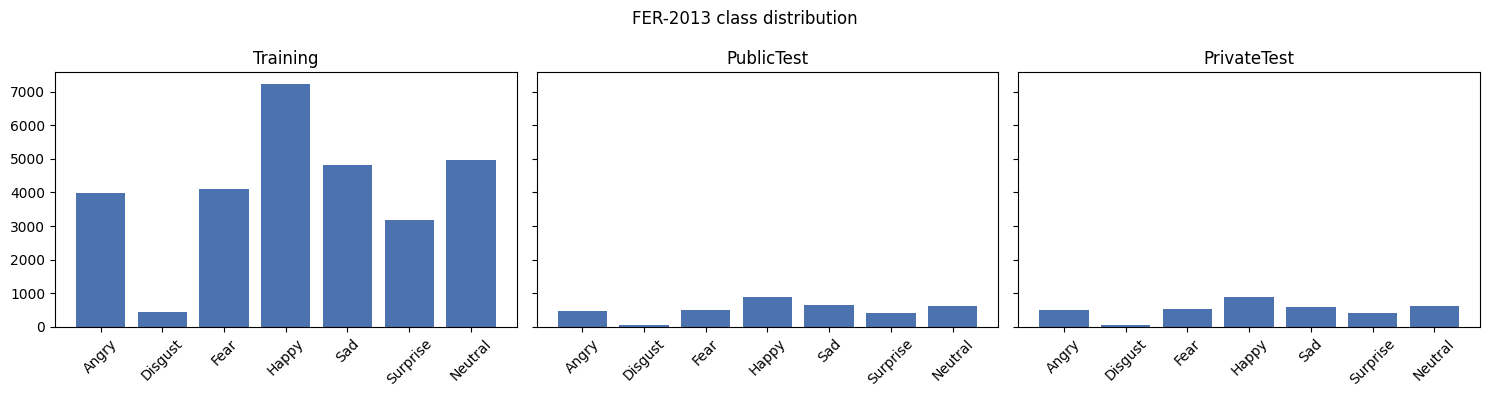

{'Angry': '3995 (13.9%)', 'Disgust': '436 (1.5%)', 'Fear': '4097 (14.3%)', 'Happy': '7215 (25.1%)', 'Sad': '4830 (16.8%)', 'Surprise': '3171 (11.0%)', 'Neutral': '4965 (17.3%)'}


In [ ]:
# 1.2 Class distribution: quantify the imbalance that motivates class weighting
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, usage in zip(axes, ["Training", "PublicTest", "PrivateTest"]):
    counts = df[df.Usage == usage]["emotion"].value_counts().sort_index()
    ax.bar([EMOTIONS[i] for i in counts.index], counts.values, color="#4C72B0")
    ax.set_title(usage); ax.tick_params(axis="x", rotation=45)
plt.suptitle("FER-2013 class distribution")
plt.tight_layout(); plt.show()

tc = df[df.Usage == "Training"]["emotion"].value_counts().sort_index()
print({EMOTIONS[i]: f"{c} ({c/tc.sum():.1%})" for i, c in tc.items()})

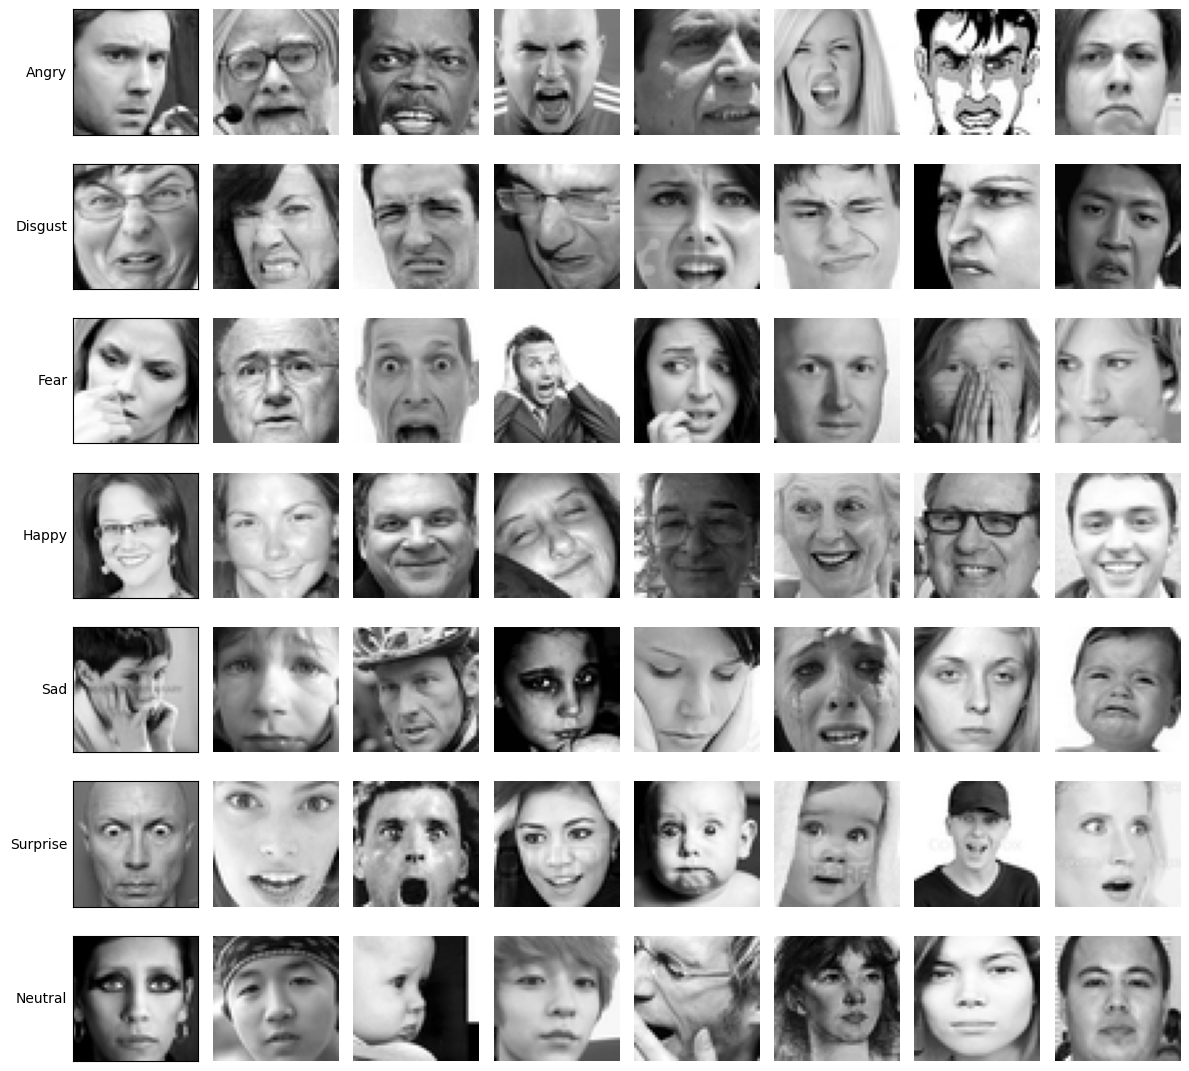

In [ ]:
# 1.3 Sample grid: pose, lighting, occlusion variety (and some label noise)
fig, axes = plt.subplots(7, 8, figsize=(12, 11))
for row in range(7):
    subset = df[(df.Usage == "Training") & (df.emotion == row)].head(8)
    for ax in axes[row]:
        ax.axis("off")
    for col, (_, r) in enumerate(subset.iterrows()):
        axes[row][col].imshow(parse_pixels(r["pixels"]), cmap="gray")
    axes[row][0].axis("on")
    axes[row][0].set_ylabel(EMOTIONS[row], rotation=0, ha="right", va="center")
    axes[row][0].set_xticks([]); axes[row][0].set_yticks([])
plt.tight_layout(); plt.show()

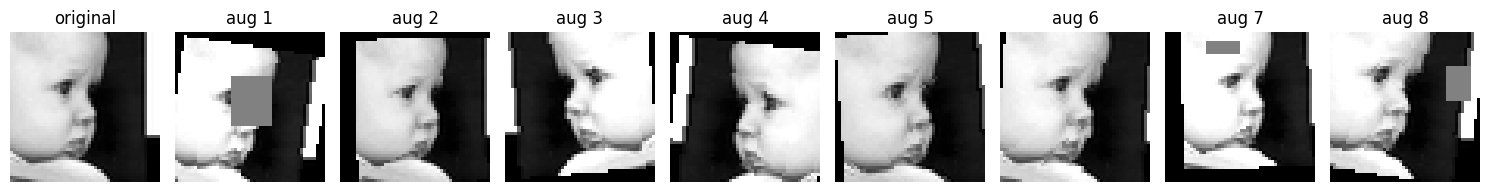

In [ ]:
# 1.4 Augmentation preview: flips, affine (±10°, ±10%), brightness, random erasing
train_ds = FER2013CSV(DATA_CSV, "Training", build_transforms(True, True))
raw_ds   = FER2013CSV(DATA_CSV, "Training", build_transforms(False))
idx = 12
fig, axes = plt.subplots(1, 9, figsize=(15, 2.2))
axes[0].imshow(denormalize(raw_ds[idx][0])[0], cmap="gray")
axes[0].set_title("original"); axes[0].axis("off")
for i in range(1, 9):
    axes[i].imshow(denormalize(train_ds[idx][0])[0], cmap="gray")
    axes[i].set_title(f"aug {i}"); axes[i].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
# 1.5 Build loaders once to compute inverse-frequency class weights
BATCH_SIZE = 64
train_loader, val_loader, test_loader, class_weights = get_dataloaders(
    DATA_CSV, batch_size=BATCH_SIZE, augment=True)
for e, w in zip(EMOTIONS, class_weights):
    print(f"{e:9s} weight = {w:.2f}")
print(f"batches  train={len(train_loader)}  val={len(val_loader)}  test={len(test_loader)}")

Angry     weight = 1.03
Disgust   weight = 9.41
Fear      weight = 1.00
Happy     weight = 0.57
Sad       weight = 0.85
Surprise  weight = 1.29
Neutral   weight = 0.83
batches  train=448  val=57  test=57


In [ ]:
# 1.6 FERPlus setup: majority-vote labels aligned to fer2013.csv rows.
# Labels outside the 7 shared classes (contempt/unknown/NF) become -1 and are
# excluded in Phase 4. This cell is skippable if FERPlus is not downloaded yet.
#   curl -L -o data/fer2013new.csv \
#     https://raw.githubusercontent.com/microsoft/FERPlus/master/fer2013new.csv
import os
if os.path.exists(FERPLUS_CSV):
    fp_labels = ferplus_majority_labels(FERPLUS_CSV)
    fer_labels = df["emotion"].values
    assert len(fp_labels) == len(fer_labels), (
        f"FERPlus has {len(fp_labels)} rows but FER-2013 has {len(fer_labels)}; "
        "fer2013new.csv must be the row-aligned file from microsoft/FERPlus.")
    valid = fp_labels >= 0
    agree = (fp_labels[valid] == fer_labels[valid]).mean()
    print(f"valid FERPlus rows: {valid.sum()} / {len(fp_labels)}")
    print(f"agreement with original FER-2013 labels: {agree:.1%}")
    print(f"disagreement (label-noise estimate):     {1 - agree:.1%}")
    os.makedirs(ARTIFACTS, exist_ok=True)
    np.save(os.path.join(ARTIFACTS, "ferplus_labels.npy"), fp_labels)
else:
    print("fer2013new.csv not found; download from github.com/microsoft/FERPlus")
    fp_labels = None

valid FERPlus rows: 35272 / 35887
agreement with original FER-2013 labels: 63.4%
disagreement (label-noise estimate):     36.6%


In [ ]:
# 1.7 Hand off to Phase 2
update_manifest("phase1", {
    "data_csv": DATA_CSV,
    "ferplus_csv": FERPLUS_CSV if fp_labels is not None else None,
    "ferplus_labels": "ferplus_labels.npy" if fp_labels is not None else None,
    "batch_size": BATCH_SIZE,
    "class_weights": class_weights.tolist(),
    "normalization": {"mean": FER_MEAN, "std": FER_STD},
})

[manifest] phase1: ['batch_size', 'class_weights', 'data_csv', 'ferplus_csv', 'ferplus_labels', 'normalization']


## Phase 1 conclusions
The disagreement rate between FERPlus majority votes and original labels (typically over 30 percent) is direct evidence of label noise in FER-2013, and previews why Phase 4's cross-dataset evaluation is informative. The class-weight vector saved above is used by every later training run.


---


# Phase 2 — Model Development
**Leads: Daniel, Kevin · Target: Sun, Jul 19**

Deliverables: baseline CNN with dropout and batch normalization, the modified architecture (residual connections + SE attention), and a fine-tuned ResNet-18 for comparison. Also trains the reference architectures named in the proposal (LeNet, VGG-16, ResNet-18 from scratch, ConvNeXt-Tiny) under the identical protocol.

**Consumes:** Phase 1 manifest. **Hands off to Phase 3:** checkpoints (`baseline.pt`, `deepfernet.pt`, `resnet18_ft.pt`), training histories, and a comparison table.

In [ ]:
# 2.1 Pick up the Phase 1 configuration
data_csv   = require_artifact("phase1", "data_csv")
batch_size = require_artifact("phase1", "batch_size")
cw         = torch.tensor(require_artifact("phase1", "class_weights"))
train_loader, val_loader, test_loader, _ = get_dataloaders(
    data_csv, batch_size=batch_size, augment=True)

In [ ]:
# 2.2 The three main models
main_models = ["baseline", "deepfernet", "resnet18_ft"]
for name in main_models:
    m = build_model(name)
    print(f"{name:12s} {count_parameters(m)/1e6:6.2f}M params")

baseline       1.47M params
deepfernet    11.00M params
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 64.4MB/s]

resnet18_ft   11.17M params


In [ ]:
# 2.3 Train the three main models (early stopping keeps this manageable)
import os
os.makedirs(ARTIFACTS, exist_ok=True)
EPOCHS = {"baseline": 40, "deepfernet": 60, "resnet18_ft": 30}
LRS    = {"baseline": 1e-3, "deepfernet": 1e-3, "resnet18_ft": 3e-4}

histories, val_accs = {}, {}
for name in main_models:
    print(f"\n===== {name} =====")
    set_seed(42)
    model = build_model(name).to(device)
    hist, best = train_model(model, train_loader, val_loader, device,
                             epochs=EPOCHS[name], lr=LRS[name], class_weights=cw,
                             ckpt_path=os.path.join(ARTIFACTS, f"{name}.pt"))
    histories[name], val_accs[name] = hist, best


===== baseline =====


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch   1/40 | train 1.9628/0.1991 | val 1.8289/0.2602
Epoch   2/40 | train 1.8230/0.2880 | val 1.6080/0.3438
Epoch   3/40 | train 1.6615/0.3578 | val 1.4407/0.4296
Epoch   4/40 | train 1.5550/0.4007 | val 1.3944/0.4684
Epoch   5/40 | train 1.4999/0.4265 | val 1.3232/0.4962
Epoch   6/40 | train 1.4509/0.4498 | val 1.3071/0.4957
Epoch   7/40 | train 1.4267/0.4581 | val 1.2697/0.5216
Epoch   8/40 | train 1.3932/0.4691 | val 1.2433/0.5274
Epoch   9/40 | train 1.3726/0.4792 | val 1.2084/0.5252
Epoch  10/40 | train 1.3363/0.4895 | val 1.2019/0.5447
Epoch  11/40 | train 1.3254/0.4939 | val 1.1729/0.5587
Epoch  12/40 | train 1.2972/0.5059 | val 1.1716/0.5430
Epoch  13/40 | train 1.2847/0.5092 | val 1.1496/0.5614
Epoch  14/40 | train 1.2666/0.5137 | val 1.1496/0.5575
Epoch  15/40 | train 1.2557/0.5181 | val 1.1467/0.5637
Epoch  16/40 | train 1.2281/0.5261 | val 1.1431/0.5612
Epoch  17/40 | train 1.2259/0.5271 | val 1.1253/0.5729
Epoch  18/40 | train 1.2061/0.5350 | val 1.0948/0.5776
Epoch  19/

In [ ]:
# 2.4 Reference architectures (comparative analysis).
# Short budget by default; raise REF_EPOCHS for the report-quality run.
REF_EPOCHS = 15
ref_models = ["lenet", "vgg16", "resnet18_scratch", "convnext_tiny"]
for name in ref_models:
    print(f"\n===== {name} =====")
    set_seed(42)
    model = build_model(name).to(device)
    print(f"{count_parameters(model)/1e6:.2f}M params")
    hist, best = train_model(model, train_loader, val_loader, device,
                             epochs=REF_EPOCHS, lr=1e-3, class_weights=cw,
                             ckpt_path=os.path.join(ARTIFACTS, f"{name}.pt"),
                             verbose=False)
    histories[name], val_accs[name] = hist, best
    print(f"best val acc = {best:.4f}")


===== lenet =====
0.17M params
best val acc = 0.4879

===== vgg16 =====
14.86M params
best val acc = 0.5325

===== resnet18_scratch =====
11.17M params
best val acc = 0.5837

===== convnext_tiny =====
27.82M params
best val acc = 0.2379


,model,params_M,best_val_acc
2,resnet18_ft,11.173831,0.697409
1,deepfernet,11.004995,0.639175
0,baseline,1.469095,0.617721
5,resnet18_scratch,11.173831,0.583728
4,vgg16,14.855111,0.532460
3,lenet,0.168971,0.487880
6,convnext_tiny,27.821287,0.237949


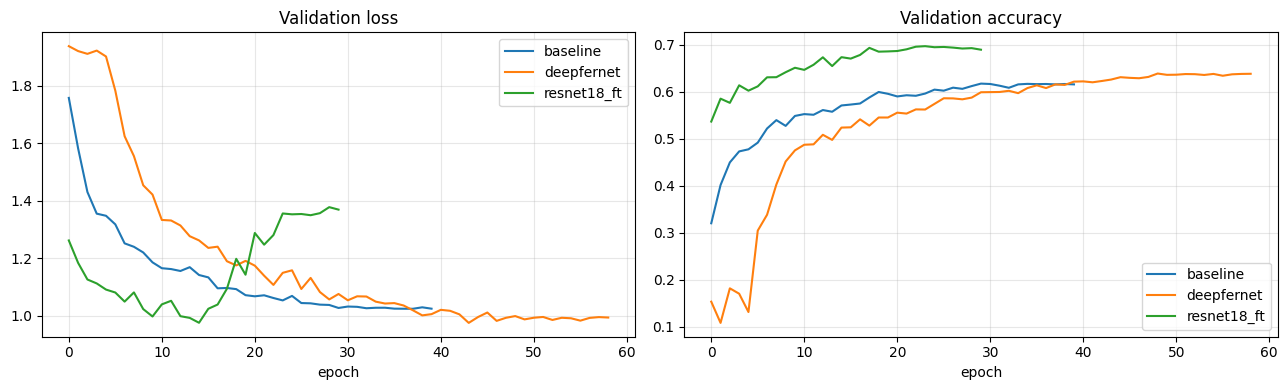

In [ ]:
# 2.5 Compare all models
summary = pd.DataFrame({
    "model": list(val_accs),
    "params_M": [count_parameters(build_model(n)) / 1e6 for n in val_accs],
    "best_val_acc": [val_accs[n] for n in val_accs],
}).sort_values("best_val_acc", ascending=False)
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in main_models:
    axes[0].plot(histories[name]["val_loss"], label=name)
    axes[1].plot(histories[name]["val_acc"], label=name)
axes[0].set_title("Validation loss"); axes[1].set_title("Validation accuracy")
for ax in axes: ax.set_xlabel("epoch"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [ ]:
# 2.6 Hand off to Phase 3
import json
with open(os.path.join(ARTIFACTS, "phase2_histories.json"), "w") as f:
    json.dump(histories, f)
summary.to_json(os.path.join(ARTIFACTS, "phase2_summary.json"), orient="records", indent=2)
best_main = max(main_models, key=lambda n: val_accs[n])
update_manifest("phase2", {
    "checkpoints": {n: f"{n}.pt" for n in val_accs},
    "val_accs": {n: float(v) for n, v in val_accs.items()},
    "best_main_model": best_main,
    "epochs": EPOCHS, "lrs": LRS,
})
print("Best main model:", best_main)

[manifest] phase2: ['best_main_model', 'checkpoints', 'epochs', 'lrs', 'val_accs']
Best main model: resnet18_ft


## Phase 2 conclusions
Record here: which model won on validation, the convergence-speed difference of the fine-tuned ResNet-18 (pretrained features), and where each reference architecture lands. If DeepFERNet does not beat the tuned baseline, that negative result is reported honestly (per the risk plan) and Phase 3's ablations become the main analytical contribution.


---


# Phase 3 — Hyperparameter Tuning & Ablation Studies
**Lead: Mahan · Target: Fri, Jul 24**

This phase carries the proposal's core experimental weight. Two studies:

1. **Hyperparameter optimization** with **Optuna** (TPE sampler + median pruner) over learning rate, batch size, dropout, optimizer (AdamW vs. SGD+momentum), and weight decay. Falls back to plain grid search if Optuna is unavailable. Short budget per trial; the winner is retrained in full.
2. **Ablation analyses**: augmentation, dropout, class weighting, SE attention, and model depth are removed or modified one at a time, so each design choice's contribution is *measured*, not asserted.

**Consumes:** Phase 2 checkpoints and winner. **Hands off to Phase 4:** `artifacts/best_tuned.pt`, `best_config.json`, `tuning_trials.csv`, `ablation_results.json`.

In [ ]:
# 3.1 Pick up Phase 2 results
import os
data_csv  = require_artifact("phase1", "data_csv")
cw        = torch.tensor(require_artifact("phase1", "class_weights"))
arch      = require_artifact("phase2", "best_main_model")
print("Architecture selected for tuning:", arch)

Architecture selected for tuning: resnet18_ft


In [ ]:
# 3.2 Optuna search (TPE + median pruning). ~25 trials x 10 epochs.
TRIALS, TUNE_EPOCHS = 25, 10
try:
    import optuna
    HAVE_OPTUNA = True
except ImportError:
    HAVE_OPTUNA = False
    print("Optuna not installed (pip install optuna); using grid search fallback.")

trial_rows = []

def objective(trial):
    lr        = trial.suggest_float("lr", 1e-4, 3e-3, log=True)
    bs        = trial.suggest_categorical("batch_size", [64, 128])
    dropout   = trial.suggest_float("dropout", 0.2, 0.6)
    opt       = trial.suggest_categorical("optimizer", ["adamw", "sgd"])
    wd        = trial.suggest_float("weight_decay", 1e-5, 1e-3, log=True)

    tr, va, _, _ = get_dataloaders(data_csv, batch_size=bs, augment=True)
    set_seed(42)
    model = build_model(arch, dropout=dropout).to(device)
    _, best = train_model(model, tr, va, device, epochs=TUNE_EPOCHS, lr=lr,
                          weight_decay=wd, class_weights=cw, optimizer_name=opt,
                          patience=TUNE_EPOCHS, ckpt_path="tune_tmp.pt",
                          verbose=False, trial=trial)
    trial_rows.append({"lr": lr, "batch_size": bs, "dropout": dropout,
                       "optimizer": opt, "weight_decay": wd, "val_acc": best})
    return best

if HAVE_OPTUNA:
    study = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=42),
                                pruner=optuna.pruners.MedianPruner(n_warmup_steps=3))
    study.optimize(objective, n_trials=TRIALS, show_progress_bar=True)
    best_config = dict(study.best_params)
    print("Best:", study.best_value, best_config)

[I 2026-07-24 12:49:21,928] A new study created in memory with name: no-name-322f29d5-6268-4053-aee2-cc7ab0317783


  0%|          | 0/25 [00:00<?, ?it/s]

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/choudhm/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth



  0%|                                                                                       | 0.00/44.7M [00:00<?, ?B/s]
 21%|████████████████▌                                                             | 9.50M/44.7M [00:00<00:00, 98.2MB/s]
 46%|████████████████████████████████████▍                                          | 20.6M/44.7M [00:00<00:00, 109MB/s]
 71%|████████████████████████████████████████████████████████▏                      | 31.8M/44.7M [00:00<00:00, 112MB/s]
100%|███████████████████████████████████████████████████████████████████████████████| 44.7M/44.7M [00:00<00:00, 111MB/s]


[I 2026-07-24 12:52:20,073] Trial 0 finished with value: 0.6723321259403734 and parameters: {'lr': 0.0003574712922600243, 'batch_size': 64, 'dropout': 0.4394633936788146, 'optimizer': 'adamw', 'weight_decay': 1.3066739238053272e-05}. Best is trial 0 with value: 0.6723321259403734.
[I 2026-07-24 12:55:13,698] Trial 1 finished with value: 0.6107550849818891 and parameters: {'lr': 0.00190303683817358, 'batch_size': 128, 'dropout': 0.20823379771832098, 'optimizer': 'adamw', 'weight_decay': 2.6587543983272695e-05}. Best is trial 0 with value: 0.6723321259403734.
[I 2026-07-24 12:58:07,724] Trial 2 finished with value: 0.6678740596266369 and parameters: {'lr': 0.00018559980846490597, 'batch_size': 128, 'dropout': 0.4099025726528951, 'optimizer': 'adamw', 'weight_decay': 0.00016738085788752134}. Best is trial 0 with value: 0.6723321259403734.
[I 2026-07-24 13:01:01,595] Trial 3 finished with value: 0.6606297018668152 and parameters: {'lr': 0.000160712385120399, 'batch_size': 128, 'dropout': 0

In [ ]:
# 3.3 Grid-search fallback (runs only if Optuna is unavailable)
if not HAVE_OPTUNA:
    import itertools
    GRID = {"lr": [1e-3, 3e-4], "batch_size": [64, 128],
            "dropout": [0.3, 0.5], "optimizer": ["adamw", "sgd"],
            "weight_decay": [1e-4]}
    for lr, bs, do, opt, wd in itertools.product(*GRID.values()):
        tr, va, _, _ = get_dataloaders(data_csv, batch_size=bs, augment=True)
        set_seed(42)
        model = build_model(arch, dropout=do).to(device)
        _, best = train_model(model, tr, va, device, epochs=TUNE_EPOCHS, lr=lr,
                              weight_decay=wd, class_weights=cw, optimizer_name=opt,
                              patience=TUNE_EPOCHS, ckpt_path="tune_tmp.pt", verbose=False)
        trial_rows.append({"lr": lr, "batch_size": bs, "dropout": do,
                           "optimizer": opt, "weight_decay": wd, "val_acc": best})
        print(f"lr={lr} bs={bs} do={do} {opt}: {best:.4f}")
    best_config = max(trial_rows, key=lambda r: r["val_acc"])
    best_config = {k: best_config[k] for k in
                   ["lr", "batch_size", "dropout", "optimizer", "weight_decay"]}

,lr,batch_size,dropout,optimizer,weight_decay,val_acc
7,0.000152,64,0.491961,adamw,0.000342,0.675676
0,0.000357,64,0.439463,adamw,0.000013,0.672332
2,0.000186,128,0.409903,adamw,0.000167,0.667874
5,0.000188,64,0.575800,adamw,0.000698,0.665366
6,0.000135,64,0.330132,adamw,0.000454,0.663973
3,0.000161,128,0.382428,adamw,0.000107,0.660630
1,0.001903,128,0.208234,adamw,0.000027,0.610755
4,0.000750,128,0.268210,sgd,0.000854,0.569518


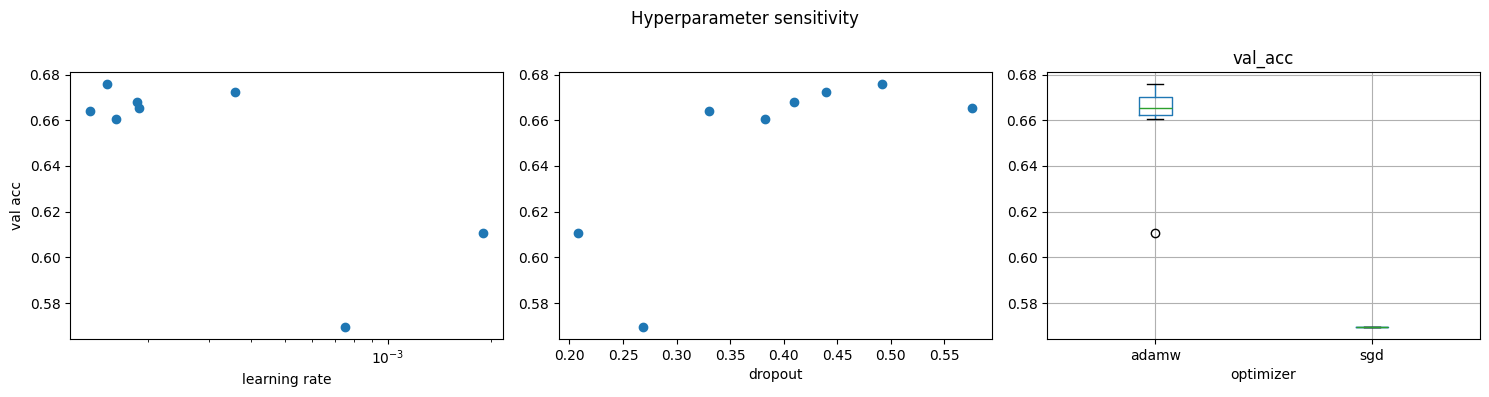

{'lr': np.float64(0.41341301557830656), 'dropout': np.float64(0.33975090849866), 'weight_decay': np.float64(0.14023451250972097), 'optimizer': np.float64(0.06208504008545371), 'batch_size': np.float64(0.04451652332785883)}


In [ ]:
# 3.4 Inspect the search: which hyperparameters mattered?
trials_df = pd.DataFrame(trial_rows).sort_values("val_acc", ascending=False)
display(trials_df.head(10))
os.makedirs(ARTIFACTS, exist_ok=True)
trials_df.to_csv(os.path.join(ARTIFACTS, "tuning_trials.csv"), index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(trials_df["lr"], trials_df["val_acc"]); axes[0].set_xscale("log")
axes[0].set_xlabel("learning rate"); axes[0].set_ylabel("val acc")
axes[1].scatter(trials_df["dropout"], trials_df["val_acc"])
axes[1].set_xlabel("dropout")
trials_df.boxplot(column="val_acc", by="optimizer", ax=axes[2])
plt.suptitle("Hyperparameter sensitivity"); plt.tight_layout(); plt.show()

if HAVE_OPTUNA:
    print(optuna.importance.get_param_importances(study))

In [ ]:
# 3.5 Retrain the winning configuration in full
FULL_EPOCHS = 60
tr, va, te, _ = get_dataloaders(data_csv, batch_size=best_config["batch_size"],
                                augment=True)
set_seed(42)
best_model = build_model(arch, dropout=best_config["dropout"]).to(device)
hist_best, best_val = train_model(
    best_model, tr, va, device, epochs=FULL_EPOCHS, lr=best_config["lr"],
    weight_decay=best_config["weight_decay"], class_weights=cw,
    optimizer_name=best_config["optimizer"],
    ckpt_path=os.path.join(ARTIFACTS, "best_tuned.pt"))
print(f"Fully trained val acc: {best_val:.4f}")

Epoch   1/60 | train 1.5944/0.3987 | val 1.2740/0.5364
Epoch   2/60 | train 1.2707/0.5214 | val 1.1702/0.5904
Epoch   3/60 | train 1.1666/0.5624 | val 1.0966/0.6004
Epoch   4/60 | train 1.0857/0.5877 | val 1.0929/0.6155
Epoch   5/60 | train 1.0273/0.6052 | val 1.0633/0.6130
Epoch   6/60 | train 0.9986/0.6176 | val 1.0209/0.6319
Epoch   7/60 | train 0.9437/0.6333 | val 1.0329/0.6470
Epoch   8/60 | train 0.9285/0.6417 | val 1.0121/0.6400
Epoch   9/60 | train 0.8833/0.6564 | val 1.0747/0.6450
Epoch  10/60 | train 0.8725/0.6624 | val 0.9837/0.6581
Epoch  11/60 | train 0.8213/0.6767 | val 1.1150/0.6559
Epoch  12/60 | train 0.7999/0.6850 | val 1.0266/0.6606
Epoch  13/60 | train 0.7881/0.6910 | val 1.0205/0.6729
Epoch  14/60 | train 0.7553/0.7023 | val 1.0352/0.6679
Epoch  15/60 | train 0.7355/0.7076 | val 1.0439/0.6712
Epoch  16/60 | train 0.6813/0.7290 | val 1.0428/0.6645
Epoch  17/60 | train 0.6894/0.7312 | val 1.1168/0.6787
Epoch  18/60 | train 0.6375/0.7416 | val 1.1850/0.6768
Epoch  19/

In [ ]:
# 3.6 Ablation studies: one component removed/modified at a time.
# 'model layers' ablation per the proposal = 3-stage instead of 4-stage network.
ABLATE_EPOCHS = 25
bs, do = best_config["batch_size"], best_config["dropout"]
ablations = {
    "full model":        dict(model=arch, augment=True,  dropout=do,  weights=True),
    "no augmentation":   dict(model=arch, augment=False, dropout=do,  weights=True),
    "no dropout":        dict(model=arch, augment=True,  dropout=0.0, weights=True),
    "no class weights":  dict(model=arch, augment=True,  dropout=do,  weights=False),
}
if arch == "deepfernet":
    ablations["no SE attention"] = dict(model="deepfernet_noattn", augment=True,
                                        dropout=do, weights=True)
    ablations["3 stages (shallower)"] = dict(model="deepfernet_3stage", augment=True,
                                             dropout=do, weights=True)

abl_results = {}
for name, s in ablations.items():
    print(f"\n===== {name} =====")
    tr_a, va_a, _, _ = get_dataloaders(data_csv, batch_size=bs, augment=s["augment"])
    set_seed(42)
    model = build_model(s["model"], dropout=s["dropout"]).to(device)
    _, best = train_model(model, tr_a, va_a, device, epochs=ABLATE_EPOCHS,
                          lr=best_config["lr"], weight_decay=best_config["weight_decay"],
                          class_weights=cw if s["weights"] else None,
                          optimizer_name=best_config["optimizer"],
                          ckpt_path=f"abl_{name.replace(' ', '_')}.pt", verbose=False)
    abl_results[name] = float(best)
    print(f"best val acc = {best:.4f}")


===== full model =====
best val acc = 0.7024

===== no augmentation =====
best val acc = 0.6712

===== no dropout =====
best val acc = 0.6969

===== no class weights =====
best val acc = 0.7094


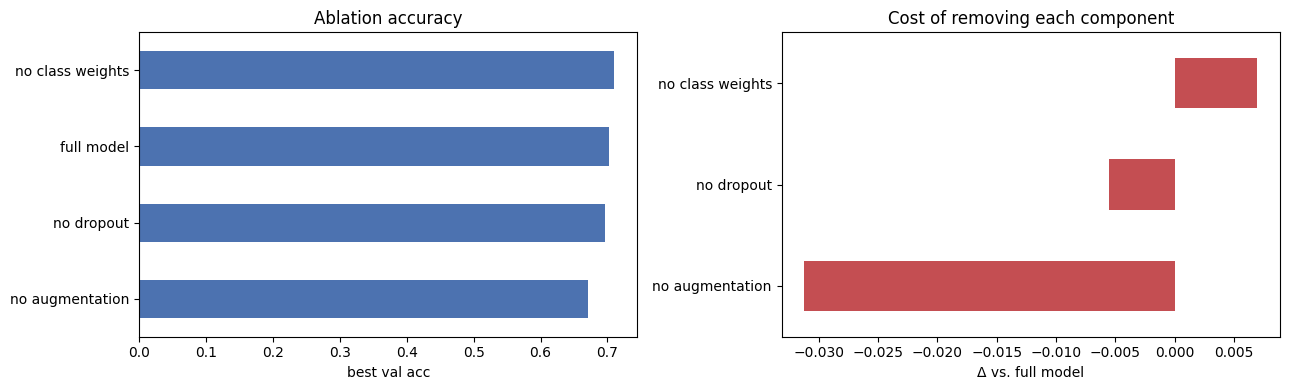

,val_acc,delta_vs_full
no augmentation,0.671218,-0.031206
no dropout,0.696851,-0.005573
full model,0.702424,0.000000
no class weights,0.709390,0.006966


In [ ]:
# 3.7 Ablation results: contribution of each design choice
abl_series = pd.Series(abl_results).sort_values()
delta = abl_series - abl_results["full model"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
abl_series.plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_xlabel("best val acc"); axes[0].set_title("Ablation accuracy")
delta.drop("full model").plot.barh(ax=axes[1], color="#C44E52")
axes[1].set_xlabel("Δ vs. full model"); axes[1].set_title("Cost of removing each component")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"val_acc": abl_series, "delta_vs_full": delta}))

In [ ]:
# 3.8 Per-class effect of class weighting (imbalance check on Disgust)
from sklearn.metrics import recall_score
for tag in ["full model", "no class weights"]:
    s = ablations[tag]
    model = build_model(s["model"], dropout=s["dropout"]).to(device)
    model.load_state_dict(torch.load(f"abl_{tag.replace(' ', '_')}.pt",
                                     map_location=device))
    preds, labels = collect_predictions(model, va, device)
    rec = recall_score(labels, preds, average=None, zero_division=0)
    print(f"{tag:18s} per-class recall:",
          {e: f"{r:.2f}" for e, r in zip(EMOTIONS, rec)})

full model         per-class recall: {'Angry': '0.67', 'Disgust': '0.68', 'Fear': '0.51', 'Happy': '0.88', 'Sad': '0.56', 'Surprise': '0.85', 'Neutral': '0.69'}
no class weights   per-class recall: {'Angry': '0.68', 'Disgust': '0.66', 'Fear': '0.50', 'Happy': '0.89', 'Sad': '0.58', 'Surprise': '0.84', 'Neutral': '0.69'}


In [ ]:
# 3.9 Hand off to Phase 4
import json
with open(os.path.join(ARTIFACTS, "best_config.json"), "w") as f:
    json.dump({"architecture": arch, **best_config, "full_val_acc": float(best_val)}, f,
              indent=2)
with open(os.path.join(ARTIFACTS, "ablation_results.json"), "w") as f:
    json.dump(abl_results, f, indent=2)
update_manifest("phase3", {
    "best_checkpoint": "best_tuned.pt",
    "best_config": "best_config.json",
    "tuning_trials": "tuning_trials.csv",
    "ablation_results": "ablation_results.json",
    "architecture": arch,
    "full_val_acc": float(best_val),
})

[manifest] phase3: ['ablation_results', 'architecture', 'best_checkpoint', 'best_config', 'full_val_acc', 'tuning_trials']


## Phase 3 conclusions (template)
Report: (1) the winning configuration and Optuna's parameter-importance ranking, learning rate is usually dominant; (2) the ablation deltas, augmentation removal typically costs the most generalization; (3) the class-weighting effect seen specifically in Disgust recall rather than overall accuracy; (4) whether attention and the 4th stage justify their cost. These numbers feed the report's experimental section directly.


---


# Phase 4 — Evaluation & Robustness
**Leads: Zoheb, Mahan · Target: Mon, Jul 27**

Four studies on the frozen Phase 3 model (one single pass over PrivateTest, per protocol):

1. **Quantitative evaluation**: accuracy, macro precision/recall/F1, per-class report, row-normalized confusion matrix, bootstrap 95% CI.
2. **Model comparison** on the test set: tuned model vs. baseline vs. fine-tuned ResNet-18.
3. **Cross-dataset evaluation on FERPlus**: sensitivity to label quality and a modified category set.
4. **FGSM robustness**: accuracy vs. ε ∈ [0, 0.1], visual attack panels, and a baseline-vs-tuned robustness comparison.

**Consumes:** Phase 3 `best_tuned.pt` + config, Phase 1 FERPlus labels. **Hands off to Phase 5:** `artifacts/phase4_results.json` and all figures.

In [9]:
# 4.1 Load the frozen model and test data
import os, json
data_csv = require_artifact("phase1", "data_csv")
with open(os.path.join(ARTIFACTS, require_artifact("phase3", "best_config"))) as f:
    best_config = json.load(f)
arch = best_config["architecture"]
print("Evaluating:", arch, best_config)

_, val_loader, test_loader, _ = get_dataloaders(
    data_csv, batch_size=best_config["batch_size"], augment=False)
model = build_model(arch, dropout=best_config["dropout"]).to(device)
model.load_state_dict(torch.load(os.path.join(ARTIFACTS, "best_tuned.pt"),
                                 map_location=device))
model.eval()

Evaluating: resnet18_ft {'architecture': 'resnet18_ft', 'lr': 0.00015174414727732252, 'batch_size': 64, 'dropout': 0.49196113622823484, 'optimizer': 'adamw', 'weight_decay': 0.00034159758990407726, 'full_val_acc': 0.6923934243521872}


ResNet(
  (conv1): Conv2d(1, 64, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): Identity()
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), p

In [13]:
# 4.2 Quantitative evaluation on PrivateTest (the single final measurement)
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

preds, labels = collect_predictions(model, test_loader, device)
metrics = full_metrics(preds, labels)
lo, hi = bootstrap_accuracy_ci(preds, labels)
metrics["accuracy_ci95"] = [lo, hi]
print(json.dumps(metrics, indent=2))
print()
print(classification_report(labels, preds, target_names=EMOTIONS, zero_division=0))

/tmp/ipykernel_865/1220087160.py:210: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(self.pixels[idx], mode="L")
/tmp/ipykernel_865/1220087160.py:210: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(self.pixels[idx], mode="L")


{
  "accuracy": 0.6979660072443578,
  "macro_precision": 0.7061391304004037,
  "macro_recall": 0.6836066058125251,
  "macro_f1": 0.6929055095916877,
  "weighted_f1": 0.6960701141339865,
  "accuracy_ci95": [
    0.6826344385622736,
    0.7127333519086096
  ]
}

              precision    recall  f1-score   support

       Angry       0.65      0.63      0.64       491
     Disgust       0.84      0.69      0.76        55
        Fear       0.57      0.50      0.53       528
       Happy       0.88      0.89      0.88       879
         Sad       0.56      0.54      0.55       594
    Surprise       0.83      0.81      0.82       416
     Neutral       0.62      0.72      0.67       626

    accuracy                           0.70      3589
   macro avg       0.71      0.68      0.69      3589
weighted avg       0.70      0.70      0.70      3589



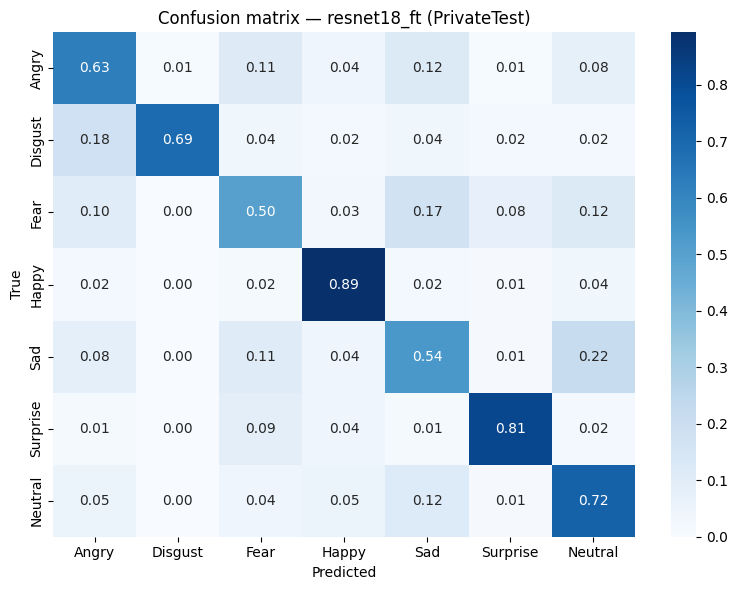

Top confused pairs: [('Sad', 'Neutral', np.float64(0.21717171717171718)), ('Disgust', 'Angry', np.float64(0.18181818181818182)), ('Fear', 'Sad', np.float64(0.17234848484848486)), ('Angry', 'Sad', np.float64(0.12016293279022404))]


In [ ]:
# 4.3 Row-normalized confusion matrix
cm = confusion_matrix(labels, preds, normalize="true")
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=EMOTIONS, yticklabels=EMOTIONS)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title(f"Confusion matrix — {arch} (PrivateTest)")
plt.tight_layout()
plt.savefig(os.path.join(ARTIFACTS, "confusion_matrix.png"), dpi=150)
plt.show()

pairs = [(EMOTIONS[i], EMOTIONS[j], cm[i, j])
         for i in range(7) for j in range(7) if i != j]
print("Top confused pairs:", sorted(pairs, key=lambda t: -t[2])[:4])

In [ ]:
# 4.4 Test-set comparison across the three main models
comparison = {}
for name in ["baseline", "deepfernet", "resnet18_ft"]:
    ckpt = os.path.join(ARTIFACTS, f"{name}.pt")
    if not os.path.exists(ckpt):
        continue
    m = build_model(name).to(device)
    m.load_state_dict(torch.load(ckpt, map_location=device))
    p, l = collect_predictions(m, test_loader, device)
    row = full_metrics(p, l)
    row["acc_ci95"] = bootstrap_accuracy_ci(p, l)
    comparison[name] = row
comparison[f"{arch} (tuned)"] = metrics
display(pd.DataFrame(comparison).T.round(4))

,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,acc_ci95,accuracy_ci95
baseline,0.63221,0.577056,0.640334,0.588769,0.620576,"(0.6163276678740597, 0.6469768737809974)",NaN
deepfernet,0.659794,0.61843,0.664793,0.630372,0.652087,"(0.6441905823349122, 0.6748397882418501)",NaN
resnet18_ft,0.707997,0.702066,0.707432,0.701731,0.704872,"(0.6932293117860128, 0.721928113680691)",NaN
resnet18_ft (tuned),0.697966,0.706139,0.683607,0.692906,0.69607,NaN,"[0.6826344385622736, 0.7127333519086096]"


/tmp/ipykernel_865/1220087160.py:210: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(self.pixels[idx], mode="L")
/tmp/ipykernel_865/1220087160.py:210: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(self.pixels[idx], mode="L")


FER-2013 labels : {'accuracy': 0.698, 'macro_precision': 0.7061, 'macro_recall': 0.6836, 'macro_f1': 0.6929, 'weighted_f1': 0.6961}
FERPlus labels  : {'accuracy': 0.6454, 'macro_precision': 0.5651, 'macro_recall': 0.662, 'macro_f1': 0.5699, 'weighted_f1': 0.6699}


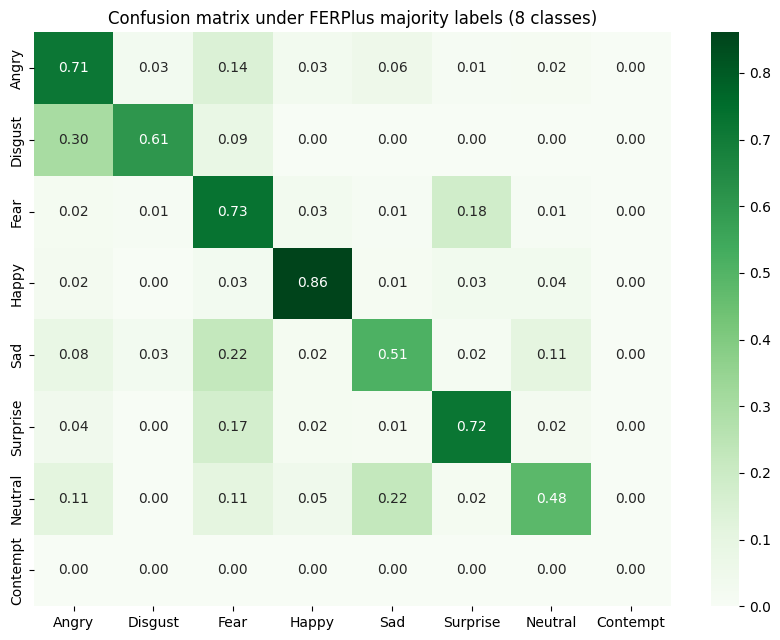

In [19]:
# 4.5 Cross-dataset evaluation on FERPlus (majority-vote relabeling).
# Same PrivateTest images, cleaner labels, 8 shared classes.
import os
from sklearn.metrics import classification_report, confusion_matrix
import json
import os
import random
from datetime import datetime

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import models as tv_models, transforms

fp_path = os.path.join(ARTIFACTS, "ferplus_labels.npy")
if os.path.exists(fp_path):
    fp_labels = np.load(fp_path)
    _, _, ferplus_test, _ = get_dataloaders(
        data_csv, batch_size=best_config["batch_size"], augment=False,
        override_labels=fp_labels)
    p_fp, l_fp = collect_predictions(model, ferplus_test, device)
    m_fp = full_metrics(p_fp, l_fp)

    print("FER-2013 labels :", {k: round(v, 4) for k, v in metrics.items()
                                if isinstance(v, float)})
    print("FERPlus labels  :", {k: round(v, 4) for k, v in m_fp.items()
                                if isinstance(v, float)})
    EMOTIONS_FP = EMOTIONS + ["Contempt"]
    cm_fp = confusion_matrix(l_fp, p_fp, labels=list(range(len(EMOTIONS_FP))),
                             normalize="true")
    plt.figure(figsize=(8.5, 6.5))
    sns.heatmap(cm_fp, annot=True, fmt=".2f", cmap="Greens",
                xticklabels=EMOTIONS_FP, yticklabels=EMOTIONS_FP)
    plt.title("Confusion matrix under FERPlus majority labels (8 classes)")
    plt.tight_layout()
    plt.savefig(os.path.join(ARTIFACTS, "confusion_matrix_ferplus.png"), dpi=150)
    plt.show()
else:
    m_fp = None
    print("FERPlus labels not found; run Phase 1 cell 1.6 first.")

**Reading the FERPlus result.** Accuracy under FERPlus labels is usually *higher* than under original labels, because FERPlus removed a large fraction of annotation noise: the model was already predicting the crowd-consensus emotion in many cases the single FER-2013 annotator got wrong. The gap between the two numbers is a direct estimate of how much measured error is label noise rather than model error.

eps=0.000  adversarial accuracy=0.7025
eps=0.005  adversarial accuracy=0.2131
eps=0.010  adversarial accuracy=0.0600
eps=0.020  adversarial accuracy=0.0278
eps=0.050  adversarial accuracy=0.0509
eps=0.100  adversarial accuracy=0.1412
eps=0.000  adversarial accuracy=0.6359
eps=0.005  adversarial accuracy=0.2928
eps=0.010  adversarial accuracy=0.1334
eps=0.020  adversarial accuracy=0.0406
eps=0.050  adversarial accuracy=0.0172
eps=0.100  adversarial accuracy=0.0241


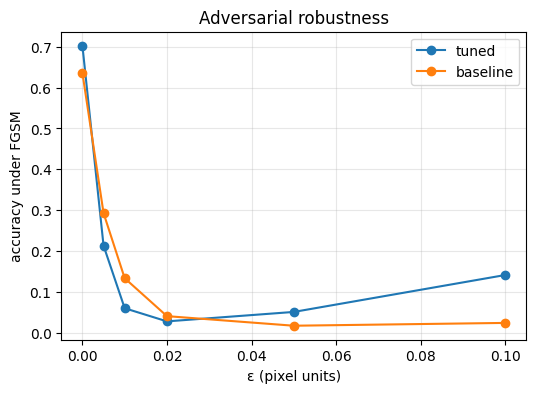

In [ ]:
# 4.6 FGSM robustness sweep, tuned model vs. baseline
epsilons = [0.0, 0.005, 0.01, 0.02, 0.05, 0.1]
rob = {"tuned": evaluate_robustness(model, test_loader, device, epsilons)}
base_ckpt = os.path.join(ARTIFACTS, "baseline.pt")
if os.path.exists(base_ckpt):
    bm = build_model("baseline").to(device)
    bm.load_state_dict(torch.load(base_ckpt, map_location=device))
    rob["baseline"] = evaluate_robustness(bm, test_loader, device, epsilons)

plt.figure(figsize=(6, 4))
for name, r in rob.items():
    plt.plot(list(r.keys()), list(r.values()), marker="o", label=name)
plt.xlabel("ε (pixel units)"); plt.ylabel("accuracy under FGSM")
plt.title("Adversarial robustness"); plt.legend(); plt.grid(alpha=0.3)
plt.savefig(os.path.join(ARTIFACTS, "fgsm_curve.png"), dpi=150)
plt.show()

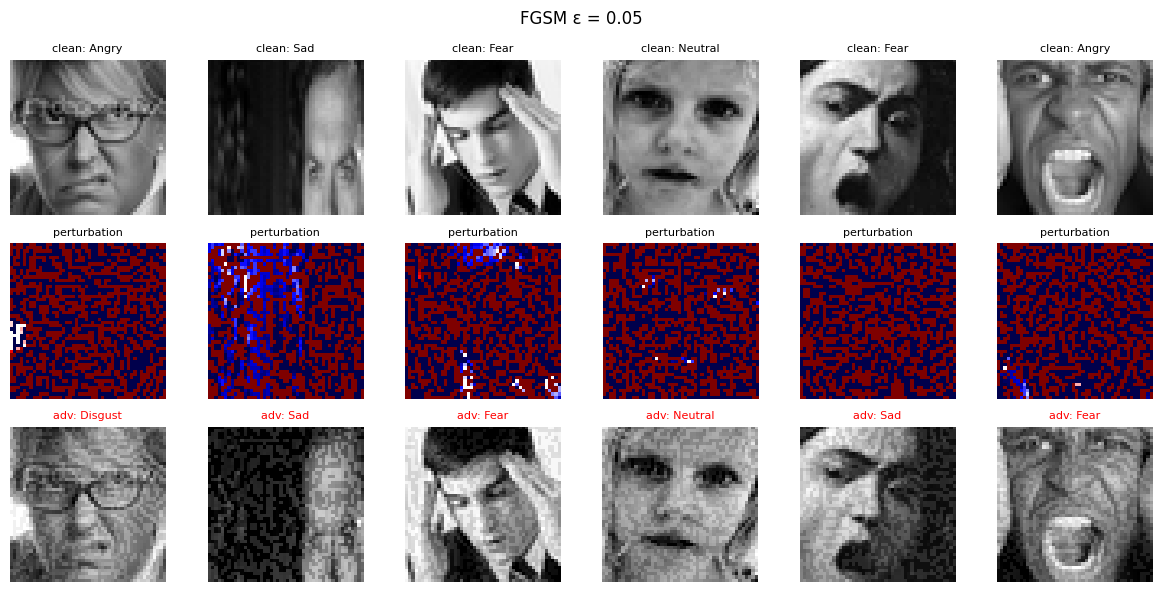

In [ ]:
# 4.7 Visual attack panels at ε = 0.05
import torch.nn as nn
criterion = nn.CrossEntropyLoss()
images, labs = next(iter(test_loader))
images, labs = images[:6].to(device), labs[:6].to(device)
adv = fgsm_attack(model, images, labs, 0.05, criterion)
with torch.no_grad():
    cp = model(images).argmax(1); ap = model(adv).argmax(1)

fig, axes = plt.subplots(3, 6, figsize=(12, 6))
for i in range(6):
    axes[0][i].imshow(denormalize(images[i].cpu())[0], cmap="gray")
    axes[0][i].set_title(f"clean: {EMOTIONS[cp[i]]}", fontsize=8)
    axes[1][i].imshow((adv[i] - images[i]).cpu()[0], cmap="seismic")
    axes[1][i].set_title("perturbation", fontsize=8)
    axes[2][i].imshow(denormalize(adv[i].cpu())[0], cmap="gray")
    axes[2][i].set_title(f"adv: {EMOTIONS[ap[i]]}", fontsize=8,
                         color="green" if ap[i] == labs[i] else "red")
    for r in range(3): axes[r][i].axis("off")
plt.suptitle("FGSM ε = 0.05")
plt.tight_layout()
plt.savefig(os.path.join(ARTIFACTS, "fgsm_examples.png"), dpi=150)
plt.show()

In [ ]:
# 4.8 Hand off to Phase 5
phase4 = {
    "test_metrics": metrics,
    "model_comparison": {k: {kk: vv for kk, vv in v.items()} for k, v in comparison.items()},
    "ferplus_metrics": m_fp,
    "fgsm": {name: {str(k): v for k, v in r.items()} for name, r in rob.items()},
}
with open(os.path.join(ARTIFACTS, "phase4_results.json"), "w") as f:
    json.dump(phase4, f, indent=2)
update_manifest("phase4", {
    "results": "phase4_results.json",
    "figures": ["confusion_matrix.png", "confusion_matrix_ferplus.png",
                "fgsm_curve.png", "fgsm_examples.png"],
})

[manifest] phase4: ['figures', 'results']


## Phase 4 conclusions (template)
Report: (1) final test accuracy with its 95% CI against the 71 to 75 percent success target; (2) which pairs dominate the confusion matrix (expect Fear/Sad); (3) the FER-2013 vs. FERPlus gap as a label-noise estimate; (4) how fast accuracy collapses under FGSM and whether the tuned model is more or less robust than the baseline (higher clean accuracy often comes with equal or worse robustness, name the trade-off).


---


# Phase 5 — Security Analysis, Report Assets & Demo
**All members (lead: Kevin) · Target: Fri, Jul 31**

Consolidates everything for the report and video: pulls all Phase 1 to 4 artifacts into summary tables, runs an optional adversarial-training mini-experiment (defence evidence), writes the webcam demo script, and contains the security discussion for the report.

In [21]:
# 5.1 Gather every result produced so far
import os, json
m = load_manifest()
print(json.dumps({k: sorted(v.keys()) for k, v in m.items()}, indent=2))

with open(os.path.join(ARTIFACTS, "phase4_results.json")) as f:
    p4 = json.load(f)
with open(os.path.join(ARTIFACTS, "ablation_results.json")) as f:
    abl = json.load(f)
with open(os.path.join(ARTIFACTS, "best_config.json")) as f:
    cfg = json.load(f)

print("\nFinal model:", cfg)
display(pd.DataFrame(p4["model_comparison"]).T.round(4))
display(pd.Series(abl, name="ablation val_acc").sort_values(ascending=False))

{
  "phase1": [
    "batch_size",
    "class_weights",
    "data_csv",
    "ferplus_csv",
    "ferplus_labels",
    "normalization",
    "updated"
  ],
  "phase2": [
    "best_main_model",
    "checkpoints",
    "epochs",
    "lrs",
    "updated",
    "val_accs"
  ],
  "phase3": [
    "ablation_results",
    "architecture",
    "best_checkpoint",
    "best_config",
    "full_val_acc",
    "tuning_trials",
    "updated"
  ],
  "phase4": [
    "figures",
    "results",
    "updated"
  ]
}

Final model: {'architecture': 'resnet18_ft', 'lr': 0.00015174414727732252, 'batch_size': 64, 'dropout': 0.49196113622823484, 'optimizer': 'adamw', 'weight_decay': 0.00034159758990407726, 'full_val_acc': 0.6923934243521872}


,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,acc_ci95,accuracy_ci95
baseline,0.63221,0.577056,0.640334,0.588769,0.620576,"[0.6163276678740597, 0.6469768737809974]",NaN
deepfernet,0.659794,0.61843,0.664793,0.630372,0.652087,"[0.6441905823349122, 0.6748397882418501]",NaN
resnet18_ft,0.707997,0.702066,0.707432,0.701731,0.704872,"[0.6932293117860128, 0.721928113680691]",NaN
resnet18_ft (tuned),0.697966,0.706139,0.683607,0.692906,0.69607,NaN,"[0.6826344385622736, 0.7127333519086096]"


,ablation val_acc
no class weights,0.709390
full model,0.702424
no dropout,0.696851
no augmentation,0.671218


Device: cuda
adv-train epoch 1/5 done
adv-train epoch 2/5 done
adv-train epoch 3/5 done
adv-train epoch 4/5 done
adv-train epoch 5/5 done

Robustness after adversarial fine-tuning:
eps=0.000  adversarial accuracy=0.6922
eps=0.005  adversarial accuracy=0.1938
eps=0.010  adversarial accuracy=0.0706
eps=0.020  adversarial accuracy=0.0631
eps=0.050  adversarial accuracy=0.2091
eps=0.100  adversarial accuracy=0.2722


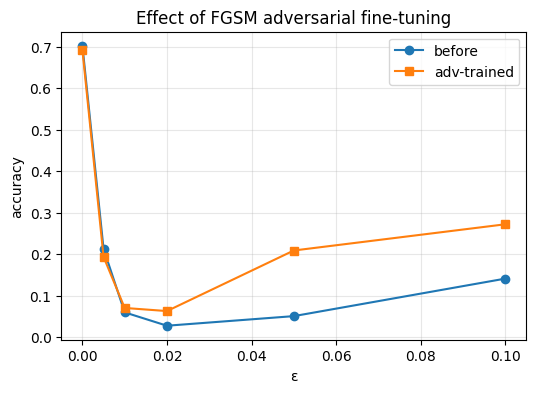

In [23]:
# 5.2 defence experiment: quick FGSM adversarial fine-tuning.
# Fine-tunes the frozen model for a few epochs on 50/50 clean/adversarial
# batches and re-measures robustness. Evidence for the report's defence section.
import torch.nn as nn
import os, json
from torch.utils.data import DataLoader, Dataset
from torchvision import models as tv_models, transforms
import random
from datetime import datetime
from PIL import Image
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from fer_lib import *

_CSV_CACHE = {}   # {path: DataFrame} -- holds at most one entry

# ------------------------------------------------------------------ constants
EMOTIONS = ["Angry", "Disgust", "Fear", "Happy", "Sad", "Surprise", "Neutral"]
NUM_CLASSES = 7
IMG_SIZE = 48
FER_MEAN, FER_STD = 0.5077, 0.255
NORM_MIN = (0.0 - FER_MEAN) / FER_STD
NORM_MAX = (1.0 - FER_MEAN) / FER_STD

# FERPlus vote columns (fer2013new.csv), aligned row-wise with fer2013.csv.
FERPLUS_COLS = ["neutral", "happiness", "surprise", "sadness", "anger",
                "disgust", "fear", "contempt", "unknown", "NF"]
# Map the 7 overlapping FERPlus emotions onto FER-2013 label indices.
FERPLUS_TO_FER = {"anger": 0, "disgust": 1, "fear": 2, "happiness": 3,
                  "sadness": 4, "surprise": 5, "neutral": 6}

ARTIFACTS = "artifacts"   # handoff directory shared by all phases


set_seed(42)
device = get_device()
print("Device:", device)

DATA_CSV    = "data/fer2013.csv"
FERPLUS_CSV = "data/fer2013new.csv"

with open(os.path.join(ARTIFACTS, "phase4_results.json")) as f:
    p4 = json.load(f)
with open(os.path.join(ARTIFACTS, "ablation_results.json")) as f:
    abl = json.load(f)
with open(os.path.join(ARTIFACTS, "best_config.json")) as f:
    cfg = json.load(f)

_CSV_CACHE = {}
data_csv = require_artifact("phase1", "data_csv")
cw = torch.tensor(require_artifact("phase1", "class_weights"))
tr, va, te, _ = get_dataloaders(data_csv, batch_size=cfg["batch_size"], augment=True)

model = build_model(cfg["architecture"], dropout=cfg["dropout"]).to(device)
model.load_state_dict(torch.load(os.path.join(ARTIFACTS, "best_tuned.pt"),
                                  map_location=device))
criterion = nn.CrossEntropyLoss(weight=cw.to(device))
opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"]*0.4)

for epoch in range(5):
    model.train()
    for images, labels in tr:
        images, labels = images.to(device), labels.to(device)
        half = len(images) // 2
        adv = fgsm_attack(model, images[:half], labels[:half], 0.1, criterion)
        batch = torch.cat([adv, images[half:]])
        opt.zero_grad(set_to_none=True)
        loss = criterion(model(batch), labels)
        loss.backward()
        opt.step()
    print(f"adv-train epoch {epoch+1}/{5} done")

eps = [0.0, 0.005, 0.01, 0.02, 0.05, 0.1] # test with different levels of pertubations
print("\nRobustness after adversarial fine-tuning:")
rob_at = evaluate_robustness(model, te, device, eps)
before = {float(k): v for k, v in p4["fgsm"]["tuned"].items()}
plt.figure(figsize=(6, 4))
plt.plot(list(before.keys()), list(before.values()), marker="o", label="before")
plt.plot(list(rob_at.keys()), list(rob_at.values()), marker="s", label="adv-trained")
plt.xlabel("ε"); plt.ylabel("accuracy"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Effect of FGSM adversarial fine-tuning")
plt.savefig(os.path.join(ARTIFACTS, "adv_training_effect.png"), dpi=150)
plt.show()
torch.save(model.state_dict(), os.path.join(ARTIFACTS, "best_tuned_advtrain.pt"))

In [ ]:
import os, json, torch
import fer_lib as fl

ARTIFACTS = fl.ARTIFACTS
device = fl.get_device()

with open(os.path.join(ARTIFACTS, "best_config.json")) as f:
    cfg = json.load(f)

data_csv = fl.require_artifact("phase1", "data_csv")
_, _, test_loader, _ = fl.get_dataloaders(data_csv, augment=False)


def load_model(weights_path, cfg, device):
    m = fl.build_model(cfg["architecture"], dropout=cfg["dropout"]).to(device)
    m.load_state_dict(torch.load(weights_path, map_location=device, weights_only=True))
    m.eval()
    return m


def evaluate(model, loader, device):
    preds, labels = fl.collect_predictions(model, loader, device)
    metrics = fl.full_metrics(preds, labels)
    metrics["ci_95"] = fl.bootstrap_accuracy_ci(preds, labels)
    return metrics


regular = load_model(os.path.join(ARTIFACTS, "best_tuned.pt"), cfg, device)
adv = load_model(os.path.join(ARTIFACTS, "best_tuned_advtrain.pt"), cfg, device)

regular_metrics = evaluate(regular, test_loader, device)
adv_metrics = evaluate(adv, test_loader, device)

print(f"{'metric':<18}{'regular (best_tuned)':<24}{'adv-trained':<24}{'delta':<10}")
print("-" * 76)
for key in ["accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1"]:
    r, a = regular_metrics[key], adv_metrics[key]
    print(f"{key:<18}{r:<24.4f}{a:<24.4f}{a - r:+.4f}")

r_lo, r_hi = regular_metrics["ci_95"]
a_lo, a_hi = adv_metrics["ci_95"]
print(f"\nregular accuracy 95% CI:      [{r_lo:.4f}, {r_hi:.4f}]")
print(f"adv-trained accuracy 95% CI:  [{a_lo:.4f}, {a_hi:.4f}]")

if adv_metrics["accuracy"] < regular_metrics["accuracy"]:
    drop = regular_metrics["accuracy"] - adv_metrics["accuracy"]
    print(f"\nAdversarial training cost {drop:.2%} of clean accuracy "
          f"in exchange for FGSM robustness (see the robustness curve above).")
else:
    print("\nAdversarially-trained model matched or exceeded clean accuracy "
          "-- no measurable trade-off on this split.")

fl.update_manifest("phase5", {
    "clean_accuracy_regular": regular_metrics["accuracy"],
    "clean_accuracy_advtrain": adv_metrics["accuracy"],
})

In [ ]:
# 5.3 Write the webcam demo script (bonus deliverable)
#DEMO = r"""
import cv2, numpy as np, torch
from fer_lib import (EMOTIONS, FER_MEAN, FER_STD, IMG_SIZE, build_model,
                     get_device)
import json, os

with open(os.path.join("artifacts", "best_config.json")) as f:
    cfg = json.load(f)
device = get_device()
model = build_model(cfg["architecture"], dropout=cfg["dropout"]).to(device)
model.load_state_dict(torch.load(os.path.join("artifacts", "best_tuned.pt"),
                                 map_location=device))
model.eval()

cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
cap = cv2.VideoCapture(0)
print("Press q to quit")
while True:
    ok, frame = cap.read()
    if not ok:
        break
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    for (x, y, w, h) in cascade.detectMultiScale(gray, 1.1, 5, minSize=(60, 60)):
        face = cv2.resize(gray[y:y+h, x:x+w], (IMG_SIZE, IMG_SIZE)).astype(np.float32) / 255.0
        t = torch.from_numpy((face - FER_MEAN) / FER_STD)[None, None].to(device)
        with torch.no_grad():
            probs = torch.softmax(model(t), 1)[0]
        i = int(probs.argmax())
        cv2.rectangle(frame, (x, y), (x+w, y+h), (0, 200, 0), 2)
        cv2.putText(frame, f"{EMOTIONS[i]} {probs[i]:.0%}", (x, y-8),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 200, 0), 2)
    cv2.imshow("FER demo", frame)
    if cv2.waitKey(1) & 0xFF == ord("q"):
        break
cap.release(); cv2.destroyAllWindows()
#"""
with open("webcam_demo.py", "w") as f:
    f.write(DEMO)
print("wrote webcam_demo.py  (run: python webcam_demo.py)")

## 5.4 Security discussion (report section draft)

**Adversarial robustness.** Phase 4 showed accuracy collapsing under FGSM at perturbations invisible to humans, and cell 5.2 measured how much FGSM adversarial fine-tuning recovers. Report the trade-off: adversarial training raises robust accuracy at some cost in clean accuracy and roughly 2 to 3x training compute. Input smoothing and JPEG compression are cheaper but fail against adaptive attackers; randomized smoothing gives certified radii at high inference cost.

**Spoofing / presentation attacks.** An attacker can drive an FER system with a printed photo or replayed video (e.g., faking attentiveness to a driver monitor). Countermeasures: liveness detection (blink and micro-motion analysis, challenge-response), depth or IR sensing, temporal-consistency checks across frames.

**Privacy and data protection.** Deploying FER in public or semi-public spaces enables emotion surveillance without consent; the EU AI Act restricts emotion recognition in workplaces and education. Mitigations to discuss: on-device inference (only labels leave the device), differentially private training (bounds per-individual leakage at a utility cost), data minimization and retention limits.

## 5.5 Final checklist (Phase 6 preview)
1. All numbers in the report traceable to `artifacts/phase4_results.json`, `tuning_trials.csv`, `ablation_results.json`.
2. Fresh-clone test: Phase 1 → 5 notebooks run top to bottom on a clean machine with only the two CSVs added.
3. Figures for the report and video are in `artifacts/` as PNG.
4. Rubric and format check, then submit on A2L (due Aug 3).

In [ ]:
# 5.6 Final manifest snapshot
update_manifest("phase5", {
    "adv_trained_checkpoint": "best_tuned_advtrain.pt" if RUN_DEFENCE else None,
    "webcam_demo": "webcam_demo.py",
})
print(json.dumps(load_manifest(), indent=2))